In [1]:
!pip install ucimlrepo numpy pandas matplotlib seaborn scikit-learn

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [3]:
digits = fetch_ucirepo(id=80)

X = digits.data.features
y = digits.data.targets

y = y.squeeze()

print("Dataset Loaded Successfully!")
print("Total Samples:", X.shape[0])
print("Total Features:", X.shape[1])
print("Target Classes:", sorted(y.unique()))

Dataset Loaded Successfully!
Total Samples: 5620
Total Features: 64
Target Classes: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (4496, 64)
Testing Data: (1124, 64)


In [10]:
knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train_scaled, y_train)

knn_pred = knn.predict(X_test_scaled)

knn_accuracy = accuracy_score(y_test, knn_pred) * 100

print("KNN Accuracy:", knn_accuracy, "%")

KNN Accuracy: 97.77580071174377 %


In [6]:
svm = SVC(kernel='rbf')

svm.fit(X_train_scaled, y_train)

svm_pred = svm.predict(X_test_scaled)

svm_accuracy = accuracy_score(y_test, svm_pred) * 100

print("SVM Accuracy:", svm_accuracy, "%")

SVM Accuracy: 98.66548042704626 %


In [7]:
print("KNN Classification Report")
print(classification_report(y_test, knn_pred))

print("SVM Classification Report")
print(classification_report(y_test, svm_pred))

KNN Classification Report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       111
           1       0.98      1.00      0.99       114
           2       1.00      1.00      1.00       111
           3       0.98      0.96      0.97       114
           4       0.98      0.99      0.99       114
           5       0.96      0.96      0.96       112
           6       0.99      1.00      1.00       112
           7       0.95      0.96      0.96       113
           8       0.97      0.94      0.95       111
           9       0.96      0.96      0.96       112

    accuracy                           0.98      1124
   macro avg       0.98      0.98      0.98      1124
weighted avg       0.98      0.98      0.98      1124

SVM Classification Report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       111
           1       0.99      0.99      0.99       114
           2       1.00   

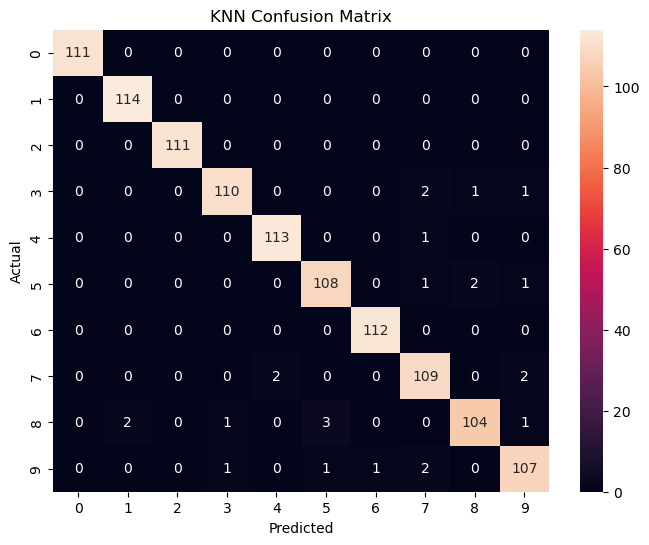

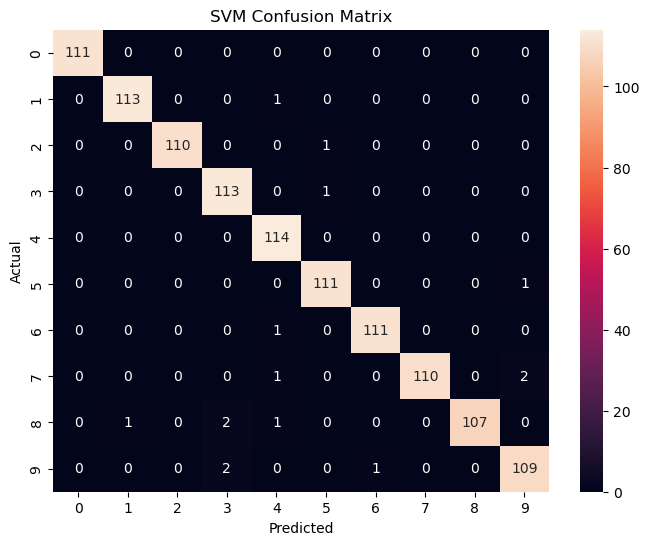

In [8]:
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test, knn_pred), annot=True, fmt='d')
plt.title("KNN Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test, svm_pred), annot=True, fmt='d')
plt.title("SVM Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

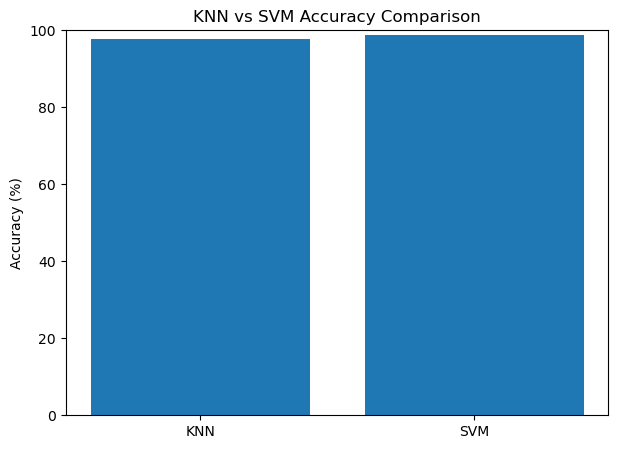

In [9]:
models = ['KNN', 'SVM']
accuracies = [knn_accuracy, svm_accuracy]

plt.figure(figsize=(7, 5))
plt.bar(models, accuracies)
plt.title("KNN vs SVM Accuracy Comparison")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.show()